# Fidelity against diversity, sentiment synthetic sets

Figure only. The numbers come from `docs/sentiment/tables/fidelity_diversity.csv`, written by `python -m src.sentiment.fidelity_diversity` from the logged SQ01, SQ02 and SQ03 results; rerun that first if a quality result changes.

Fidelity = share of texts that the real-only SR01 MARBERT ensemble labels with the requested sentiment. For the real row it is that ensemble's accuracy on S1 dev, so the real star is a reference point. Arrows go from zero-shot (SG01) to few-shot (SG02) for the same generator.

In [1]:
import csv
import os
from pathlib import Path

import matplotlib.pyplot as plt

# Run from the repo root whether the notebook is opened from notebooks/ or the root.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

with open("docs/sentiment/tables/fidelity_diversity.csv", encoding="utf-8") as f:
    rows = [{k: (v if k == "set" else float(v)) for k, v in r.items()} for r in csv.DictReader(f)]
for r in rows:
    r["run"] = "real" if r["set"].startswith("S1") else r["set"].split()[0].lower()
    r["generator"] = "real" if r["run"] == "real" else r["set"].split()[1].lower().replace("-", "")
by = {(r["run"], r["generator"]): r for r in rows}
[r["set"] for r in rows]

['S1 real (reference)',
 'SG01 Jais-2',
 'SG01 Fanar',
 'SG01 Qwen3',
 'SG01 Aya',
 'SG02 Fanar',
 'SG02 Qwen3',
 'SG02 Aya']

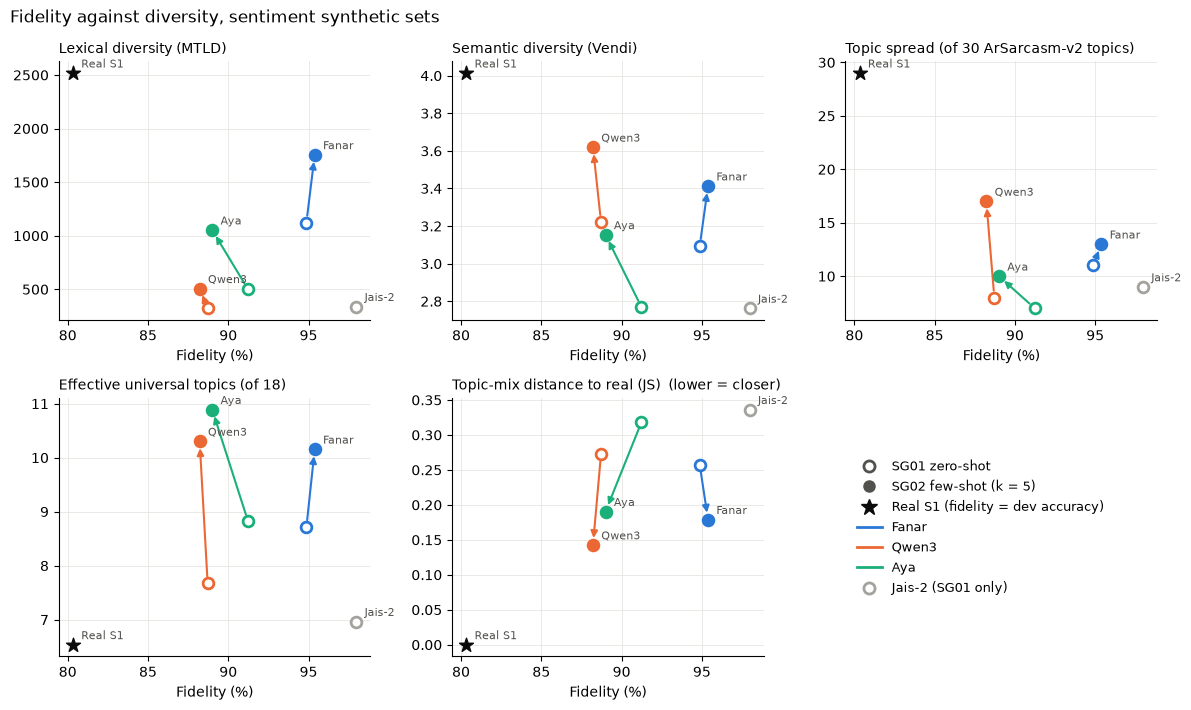

In [2]:
# Dataviz reference palette: slots 1-3 for the three SG02 generators (all-pairs cap for scatter is three);
# Jais-2 (SG01 only) folds to the neutral gray, real is ink.
COLORS = {"fanar": "#2a78d6", "qwen3": "#eb6834", "aya": "#1baf7a", "jais2": "#a3a29c", "real": "#0b0b0b"}
NAMES = {"fanar": "Fanar", "qwen3": "Qwen3", "aya": "Aya", "jais2": "Jais-2"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
MEASURES = [  # column, panel title, higher = more diverse?
    ("mtld", "Lexical diversity (MTLD)", True),
    ("vendi", "Semantic diversity (Vendi)", True),
    ("topic_spread", "Topic spread (of 30 ArSarcasm-v2 topics)", True),
    ("effective_named", "Effective universal topics (of 18)", True),
    ("distance_to_real", "Topic-mix distance to real (JS)", False),
]

fig, axes = plt.subplots(2, 3, figsize=(12, 7.2))
for ax, (key, title, higher) in zip(axes.flat, MEASURES):
    ax.grid(True, color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    for g in ("fanar", "qwen3", "aya"):
        a, b = by[("sg01", g)], by[("sg02", g)]
        ax.annotate("", xy=(b["fidelity"] * 100, b[key]), xytext=(a["fidelity"] * 100, a[key]),
                    arrowprops={"arrowstyle": "-|>", "color": COLORS[g], "lw": 1.5, "shrinkA": 5, "shrinkB": 5})
    for r in rows:
        x, y, c = r["fidelity"] * 100, r[key], COLORS[r["generator"]]
        if r["run"] == "real":
            ax.scatter(x, y, s=110, marker="*", color=c, zorder=4)
            ax.annotate("Real S1", (x, y), xytext=(6, 4), textcoords="offset points", fontsize=8, color=INK2)
        else:
            ax.scatter(x, y, s=60, facecolor=c if r["run"] == "sg02" else "white", edgecolor=c, lw=2, zorder=4)
            if r["run"] == "sg02" or r["generator"] == "jais2":
                ax.annotate(NAMES[r["generator"]], (x, y), xytext=(6, 4), textcoords="offset points", fontsize=8, color=INK2)
    ax.set_xlabel("Fidelity (%)")
    ax.set_title(title + ("" if higher else "  (lower = closer)"), loc="left", fontsize=10)

key_ax = axes.flat[-1]
key_ax.axis("off")
handles = [plt.Line2D([], [], marker="o", ls="", ms=8, mfc="white", mec=INK2, mew=2, label="SG01 zero-shot"),
           plt.Line2D([], [], marker="o", ls="", ms=8, color=INK2, label="SG02 few-shot (k = 5)"),
           plt.Line2D([], [], marker="*", ls="", ms=12, color=INK, label="Real S1 (fidelity = dev accuracy)")]
handles += [plt.Line2D([], [], color=COLORS[g], lw=2, label=NAMES[g]) for g in ("fanar", "qwen3", "aya")]
handles.append(plt.Line2D([], [], marker="o", ls="", ms=8, mfc="white", mec=COLORS["jais2"], mew=2, label="Jais-2 (SG01 only)"))
key_ax.legend(handles=handles, loc="center left", frameon=False, fontsize=9)
fig.suptitle("Fidelity against diversity, sentiment synthetic sets", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
plt.show()